# 04 — Review sentiment (Amazon Reviews 2023, Grocery and Gourmet Food)

**Question:** what do grocery customers complain about, and can we flag negative reviews automatically?

Produced by two scripts; this notebook reads their outputs:
- `python -m src.nlp.sample_reviews` — uniform random 30K sample of the whole 14M-review file (A22)
- `python -m src.nlp.sentiment` — models, evaluation, plots, themes, MLflow

These reviewers are **not** the dunnhumby households (A09): the two sources are never joined per person.

### Design
- **Labels from stars (A08):** 1–2 negative, 3 neutral, 4–5 positive. A proxy: some 5-star reviews contain complaints.
- **Split by product:** no product appears in two of train / validation / test, so the model cannot score well by
  memorising product names. Stratified by label.
- **Metric: macro-F1**, the average F1 of the three classes. Accuracy would reward predicting "positive" for everything.
- Hyper-parameters and model choice by 5-fold cross-validation; test used once, with a 95% bootstrap interval.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, display
pd.set_option("display.width", 220)
meta = json.loads((ROOT / "data/sampled/amazon_grocery_reviews_sample_meta.json").read_text())
res = json.loads((ROOT / "reports/sentiment_results.json").read_text())
FIG = ROOT / "reports" / "figures"
{k: v for k, v in meta.items() if k != "source"}

{'file_bytes': 5973991903,
 'sample_size': 30000,
 'seed': 42,
 'C': 200,
 'draws': 64000,
 'rejected_by_length': 32310,
 'duplicates': 34,
 'ineligible': 27,
 'short_prev_lines': 0,
 'acceptance_rate': 0.482,
 'mean_record_bytes_est': 416.8,
 'est_total_records': 14334514,
 'method': 'random byte offsets + length-bias rejection sampling, without replacement'}

## 1. The sample

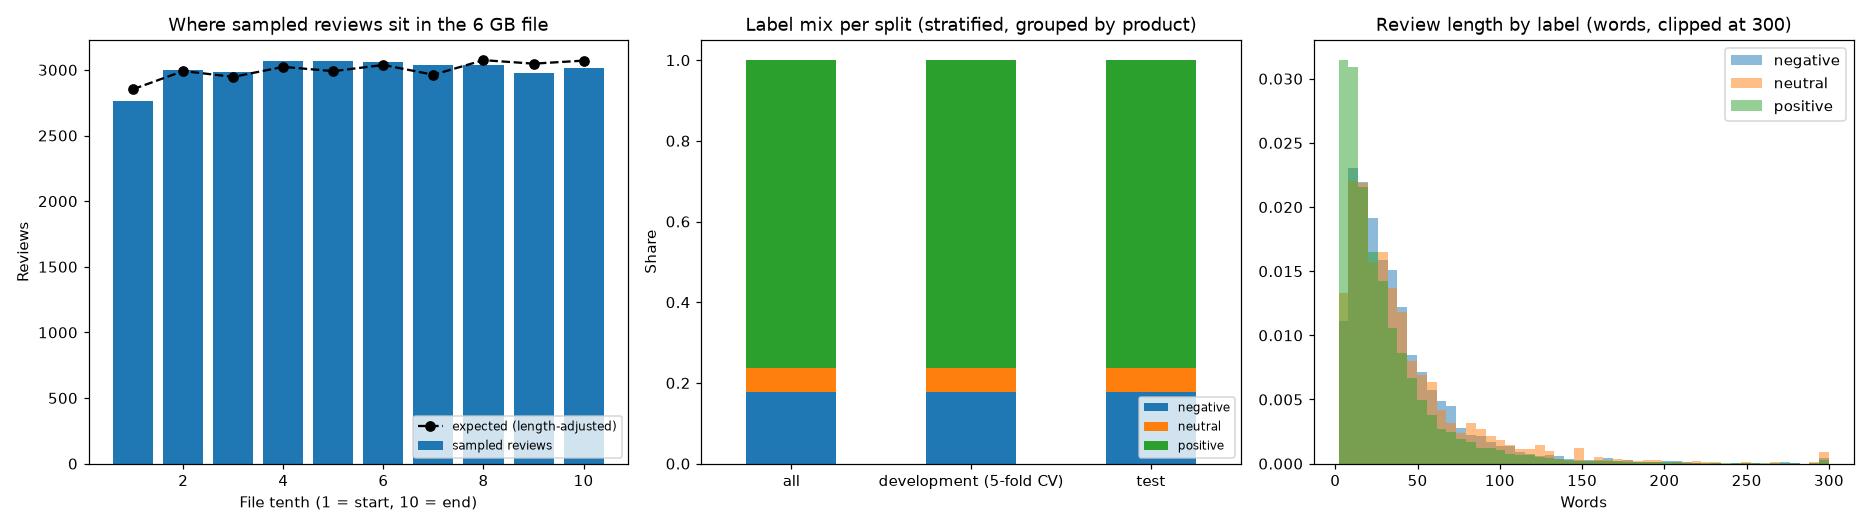

In [2]:
display(Image(FIG / "sentiment_data.png"))

In [3]:
print(res["reviews"], "reviews after removing", res["duplicates_dropped"], "duplicate texts; splits:", res["splits"])
res["label_share"]

29998 reviews after removing 2 duplicate texts; splits: {'development_cv': 25713, 'test': 4285, 'cv_folds': 5}


{'positive': 0.7619, 'negative': 0.1775, 'neutral': 0.0606}

**Reading the sample**
- 30,000 reviews drawn at random positions of the whole 6 GB file (A22). The estimated population, 14.33M reviews,
  matches the published size of the category (14.3M), and no record was shorter than the bias-correction bound.
- Left plot: reviews per tenth of the file follow the length-adjusted expectation. The first tenth has fewer
  because its reviews are longer (454 vs ~430 bytes), so fewer reviews fit in the same bytes; not a sampling gap.
- Labels: 76% positive, 18% negative, 6% neutral. Accuracy alone would be misleading (a model that always says
  "positive" gets 76%), hence macro-F1.
- Reviews span 2005–2023, most from 2019–2022.

## 2. Model comparison (5-fold CV on development) and test result

In [4]:
print("C chosen by 5-fold CV:", res["C"], "| selected:", res["best"], "| star titles removed:", res["star_titles_removed"])
display(pd.DataFrame(res["cv"]).T)
pd.DataFrame(res["test"]).T

C chosen by 5-fold CV: {'tfidf_logreg': 1, 'tfidf_word_char_logreg': 1} | selected: tfidf_logreg | star titles removed: 3035


,mean_macro_f1,std_macro_f1,per_fold,folds_won
majority_class,0.288273,0.000009,"[0.288, 0.288, 0.288, 0.288, 0.288]",0
complement_nb,0.631421,0.011168,"[0.623, 0.635, 0.621, 0.652, 0.626]",0
tfidf_logreg,0.69482,0.006031,"[0.69, 0.697, 0.694, 0.689, 0.705]",4
tfidf_word_char_logreg,0.690686,0.00559,"[0.686, 0.695, 0.683, 0.692, 0.698]",1


,macro_f1,accuracy,balanced_accuracy,f1_negative,f1_neutral,f1_positive,macro_f1_ci
majority_class,0.2883,0.762,0.3333,0.0,0.0,0.8649,"[0.2855, 0.2911]"
complement_nb,0.6291,0.8784,0.6387,0.7659,0.1775,0.944,"[0.6077, 0.6504]"
tfidf_logreg,0.6894,0.8611,0.7238,0.7669,0.3645,0.9369,"[0.6686, 0.7097]"
tfidf_word_char_logreg,0.6868,0.8635,0.7162,0.7687,0.3533,0.9383,"[0.6665, 0.7059]"


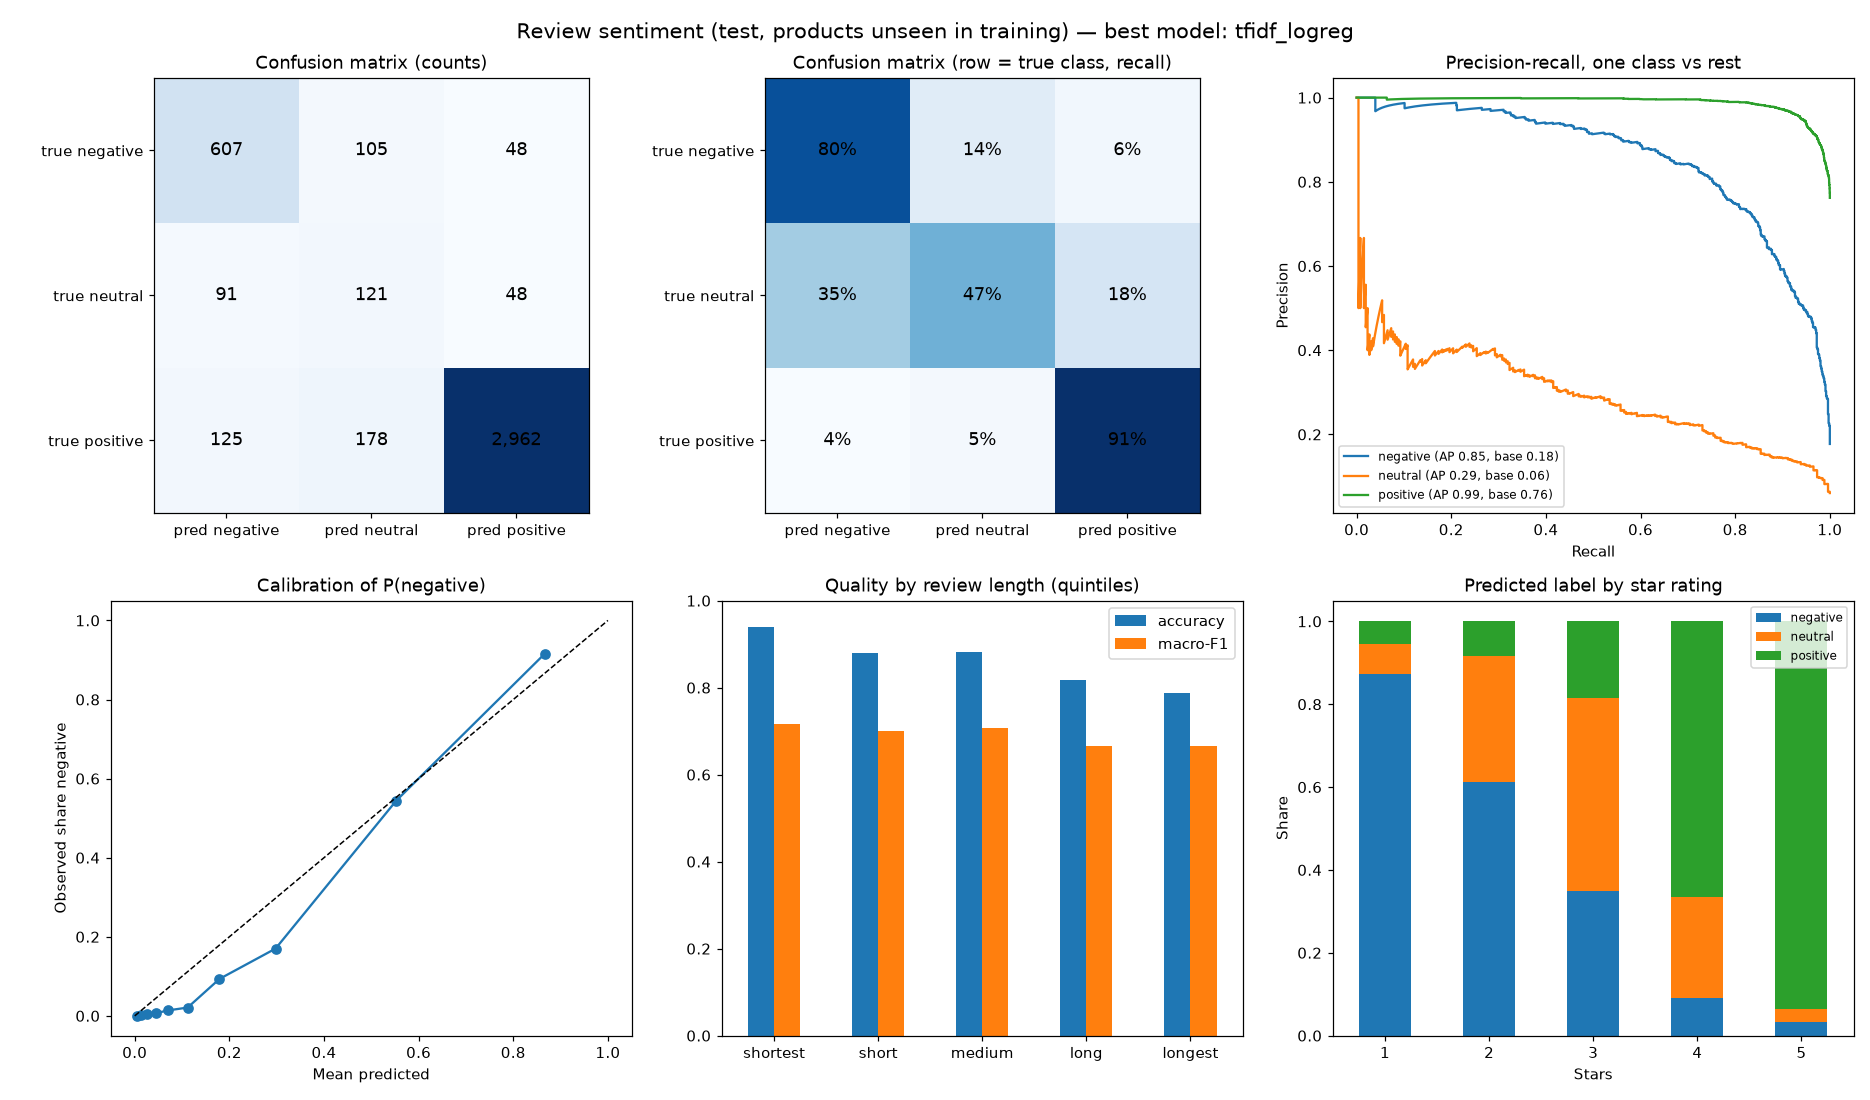

In [5]:
display(Image(FIG / "sentiment_diagnostics.png"))

**Reading the results**
- **A label leak was found and removed first (A23).** 10% of reviews have auto-generated titles ("Five Stars",
  "Two Stars") that equal the label. The first model's top features were exactly those phrases; its test macro-F1 of
  0.715 was partly reading the answer. With those titles removed: **0.689 (95% CI 0.669–0.710)**.
- Word TF-IDF + logistic regression wins the 5-fold CV (0.695 ± 0.006, 4 of 5 folds). Adding character n-grams
  does not help (0.691); Naive Bayes 0.631; always-positive 0.288.
- **Negative reviews are found reliably:** recall 0.80, precision 0.74, average precision 0.85 (base rate 0.18).
  This is the class that matters for complaint handling.
- **Neutral is the weak class (F1 0.36):** 3-star reviews mix praise and complaints ("good but too sweet"). The bottom-right
  plot shows the model splits them between all three labels, which is a fair reading of the text.
- Quality falls slightly with review length: long reviews tell a story with both good and bad points.
- **Calibration:** balanced class weights make P(negative) slightly high in the middle range, so the model predicts
  ~8% more negatives than there are. Rankings are unaffected; business rates below use observed stars instead.

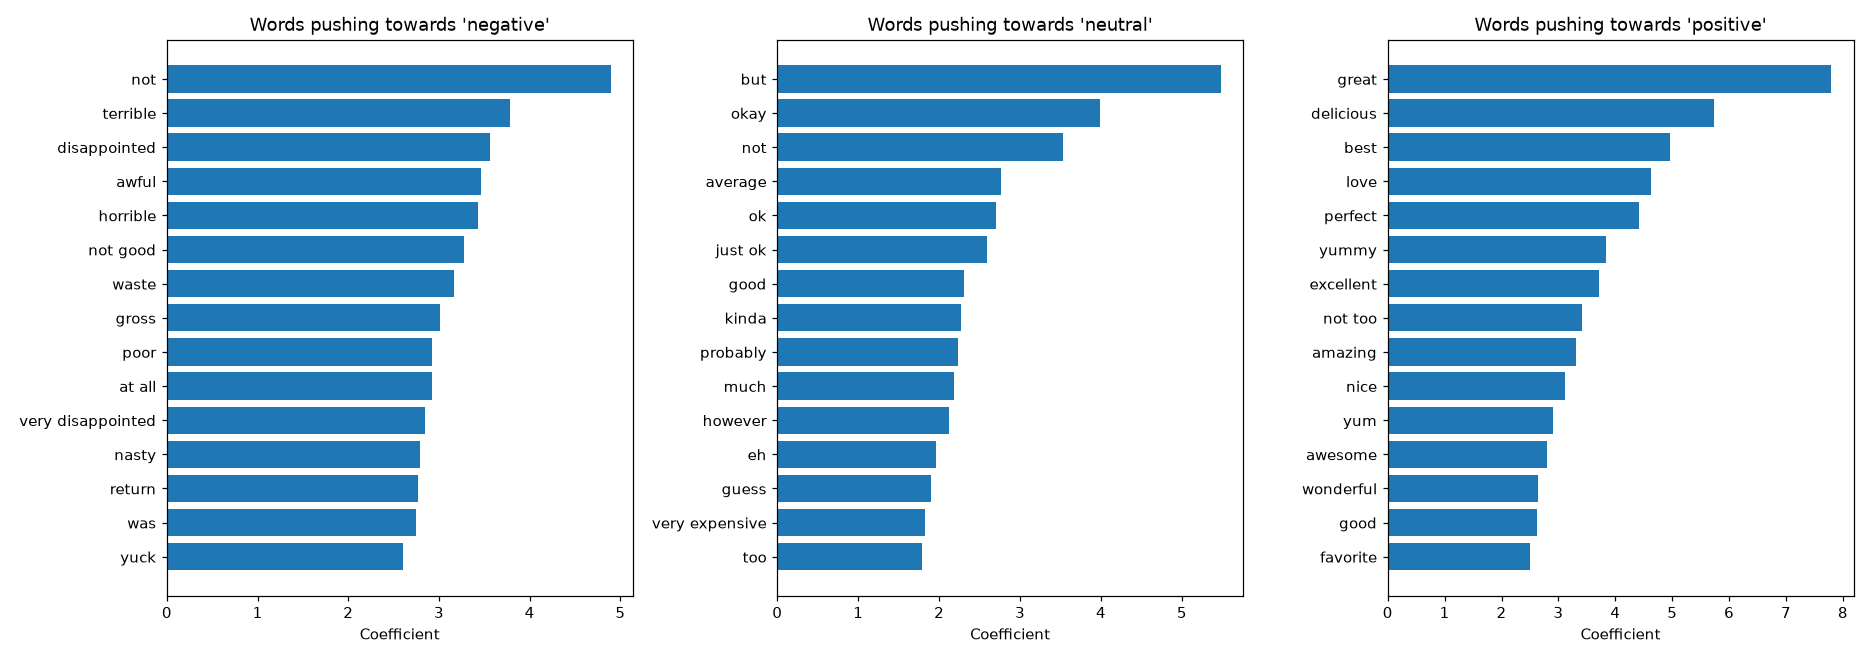

In [6]:
display(Image(FIG / "sentiment_top_words.png"))

After the fix, the model reads real language: "not", "terrible", "disappointed", "waste" (negative); "but", "okay",
"just ok", "however" (neutral); "great", "delicious", "love" (positive). Bigrams handle simple negation:
"not good" pushes negative while "not too" (e.g. "not too sweet") and "not bad" push positive.

## 3. What customers complain about

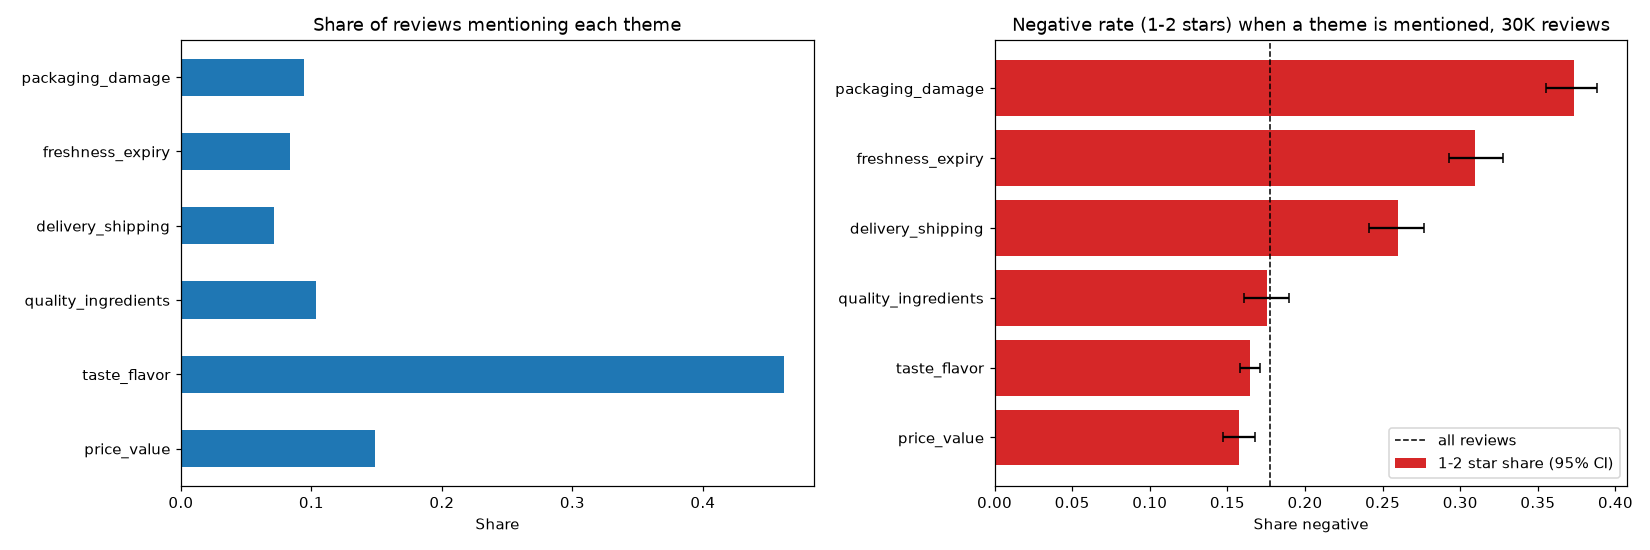

,reviews,share_of_reviews,negative_rate,negative_rate_ci,share_of_all_negatives,negative_rate_model_test
price_value,4466,0.1489,0.1572,"[0.146888, 0.167605]",0.1318,0.1616
taste_flavor,13853,0.4618,0.1644,"[0.158016, 0.170759]",0.4277,0.1803
quality_ingredients,3104,0.1035,0.1753,"[0.160438, 0.189755]",0.1021,0.1788
delivery_shipping,2149,0.0716,0.2597,"[0.241042, 0.276652]",0.1048,0.3238
freshness_expiry,2508,0.0836,0.3098,"[0.292644, 0.327562]",0.1459,0.3471
packaging_damage,2836,0.0945,0.3734,"[0.355078, 0.388223]",0.1988,0.4625


In [7]:
display(Image(FIG / "sentiment_themes.png"))
pd.DataFrame(res["themes"]).T

**What drives negative reviews** (all 30K reviews, observed 1–2 star share, 95% CI)
- **Packaging / damage: 37%** negative vs 18% overall, about twice the baseline, and 20% of all negative reviews.
- **Freshness / expiry: 31%** and **delivery / shipping: 26%**.
- Taste is mentioned most (46% of reviews) but is *not* more negative than average; price and quality neither.

So for online grocery the product itself rarely disappoints; **what happens between warehouse and doorstep** does
(crushed boxes, leaks, stale or near-expiry items, late deliveries). That is a logistics problem: protective packaging
for fragile/liquid items, temperature and shelf-life checks at dispatch, and delivery-time reliability would address
the categories with the highest negative rates.

Caveats: themes are transparent keyword rules (a review can mention several); mentioning "box" is not proof that
the box caused the rating. The numbers show association, not cause.

## 4. Using the model

In [8]:
import joblib
m = joblib.load(ROOT / "artifacts/sentiment_model.joblib")   # trained by this project (joblib unpickles code)
texts = ["Great taste and arrived quickly, will buy again.",
         "The box arrived crushed and the bag was leaking.",
         "It's ok, a bit too sweet for me."]
pd.DataFrame(m["model"].predict_proba(texts), columns=m["classes"], index=texts).round(3)

,negative,neutral,positive
"Great taste and arrived quickly, will buy again.",0.011,0.010,0.979
The box arrived crushed and the bag was leaking.,0.940,0.031,0.029
"It's ok, a bit too sweet for me.",0.018,0.961,0.021


## Summary

| | Result |
|---|---|
| Data | 30,000 uniform random reviews out of ~14.3M (A22) |
| Model | Word TF-IDF + logistic regression, chosen by 5-fold product-grouped CV |
| Test macro-F1 | 0.689 (95% CI 0.669–0.710) vs 0.288 always-positive |
| Negative reviews | recall 0.80, precision 0.74 |
| Main finding | Packaging/damage, freshness and delivery reviews are 1.5–2× more often negative than average |

The model is served by the API (`POST /predict/sentiment`). A transformer (e.g. DistilBERT) would likely improve the
neutral class; it was not used here because of disk space and CPU-only training, and is noted as future work.